# RSNA Knee Abnormality Detection — Pregunta 1
**Clasificación multietiqueta de 12 hallazgos en RMN de rodilla con aprendizaje débilmente supervisado**

Antes de ejecutar:
1. `Settings → Accelerator → GPU T4 x2`
2. `Settings → Internet → On`
3. Ejecutar con **`Save Version → Save & Run All`** (en una sesión interactiva `/kaggle/working` se borra al reiniciar el kernel).


# 0. Entorno y configuración

In [1]:
# Dependencias que no trae la imagen de Kaggle
!pip install -q langdetect==1.0.9 sentence-transformers

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# Imports, semilla global y configuracion unica del experimento
import os, re, gc, json, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

CFG = {
    'root'        : '/kaggle/input/competitions/rsna-knee-abnormality-detection',
    'out'         : '/kaggle/working',
    'embed_model' : 'paraphrase-multilingual-mpnet-base-v2',
    'nllb_model'  : 'facebook/nllb-200-distilled-600M',
    'planes'      : ['Sagittal', 'Coronal'],
    'top_k'       : 3,
    'min_sim'     : 0.35,
    'p_prior'     : 0.25,
    'n_folds'     : 5,
    'pool_size'   : 1200,
    'subset_size' : 600,
    'subset_ext'  : 1200,
    'img_size'    : 224,
    'n_slices'    : 16,
    'batch_size'  : 16,
    'epochs'      : 20,
    'epochs_abl'  : 15,
    'lr_scratch'  : 3e-4,
    'lr_transfer' : 1e-4,
    'label_cols'  : ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA',
                     'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's",
                     'Contusion', 'Fracture'],
}
LABELS = CFG['label_cols']
IN_CH = len(CFG['planes']) * CFG['n_slices']
os.makedirs(CFG['out'], exist_ok=True)

import sklearn, transformers
print('device :', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU')
print('torch  :', torch.__version__, '| transformers:', transformers.__version__, '| sklearn:', sklearn.__version__)
print('planos :', CFG['planes'], '->', IN_CH, 'canales de entrada')

device : cuda | Tesla T4
torch  : 2.11.0+cu128 | transformers: 5.16.1 | sklearn: 1.6.1
planos : ['Sagittal', 'Coronal'] -> 32 canales de entrada


# 1. Datos: dos planos por estudio
Usamos dos: **sagital y coronal**,
ambos fluid-sensitive con supresión de grasa (DP/T2 fat-sat). Si un estudio no tiene la variante estricta,
se acepta la misma orientación sin supresión de grasa (`tier = 1`).

In [3]:
# Seleccion de una serie sagital y una coronal por estudio, con respaldo cuando falta la variante estricta
train = pd.read_csv(f"{CFG['root']}/train.csv")
train_series = pd.read_csv(f"{CFG['root']}/train_series.csv")
series_root = f"{CFG['root']}/train_series"
gold_ids = set(train.loc[train[LABELS].notna().any(axis=1), 'StudyInstanceUID'])

def count_instances(s, se):
    p = os.path.join(series_root, s, se)
    return len(os.listdir(p)) if os.path.isdir(p) else 0

def pick_plane(plane):
    strict = train_series[(train_series['Anatomical_Plane'] == plane) &
                          (train_series['Fluid_Sensitive'] == 1) &
                          (train_series['Fat_Suppression'] == 1)].copy()
    strict['tier'] = 0
    fb = train_series[(train_series['Anatomical_Plane'] == plane) &
                      (train_series['Fluid_Sensitive'] == 0) &
                      (train_series['Fat_Suppression'] == 0)].copy()
    fb['tier'] = 1
    cand = pd.concat([strict, fb], ignore_index=True)
    cand['n_inst'] = cand.apply(lambda r: count_instances(r['StudyInstanceUID'], r['SeriesInstanceUID']), axis=1)
    cand = cand[cand['n_inst'] >= 10]
    best = (cand.sort_values(['tier', 'n_inst'], ascending=[True, False])
                .drop_duplicates('StudyInstanceUID', keep='first'))
    return best.set_index('StudyInstanceUID')[['SeriesInstanceUID', 'n_inst', 'tier']]

sag = pick_plane('Sagittal').add_prefix('sag_')
cor = pick_plane('Coronal').add_prefix('cor_')
both = sag.join(cor, how='inner')

print('Estudios en el dataset :', train['StudyInstanceUID'].nunique())
print('Series en el dataset   :', len(train_series))
print('Estudios con ambos     :', len(both))
print('Gold con ambos         :', len(set(both.index) & gold_ids), '/', len(gold_ids))
print('Respaldo usado         : sagital', int(both['sag_tier'].sum()), '| coronal', int(both['cor_tier'].sum()))

Estudios en el dataset : 4407
Series en el dataset   : 24371
Estudios con ambos     : 4407
Gold con ambos         : 58 / 58
Respaldo usado         : sagital 257 | coronal 159


In [4]:
# Tabla maestra: rutas de las dos series, reporte, 12 etiquetas, idioma y longitud del informe
from langdetect import detect, LangDetectException

def safe_detect(t):
    try:
        return detect(t[:500])
    except LangDetectException:
        return 'unknown'

master = both.reset_index().merge(train[['StudyInstanceUID', 'Report'] + LABELS], on='StudyInstanceUID', how='left')
master['has_gold'] = master[LABELS].notna().any(axis=1)
master['lang'] = master['Report'].apply(safe_detect)
master['rep_len'] = master['Report'].str.len()
master['sag_path'] = master.apply(lambda r: os.path.join(series_root, r['StudyInstanceUID'], r['sag_SeriesInstanceUID']), axis=1)
master['cor_path'] = master.apply(lambda r: os.path.join(series_root, r['StudyInstanceUID'], r['cor_SeriesInstanceUID']), axis=1)

gold_master = master[master['has_gold']].copy().reset_index(drop=True)
PREV_GOLD = gold_master[LABELS].mean()

print('Tabla maestra:', master.shape, '| gold:', len(gold_master))
print('Idiomas:', master['lang'].value_counts().to_dict())

Tabla maestra: (4407, 25) | gold: 58
Idiomas: {'en': 1736, 'es': 682, 'tr': 546, 'hr': 406, 'el': 321, 'de': 262, 'bg': 220, 'nl': 153, 'fr': 81}


# Análisis exploratorio de datos (EDA)

Entender mas de la data

## EDA 1 — Estudios por idioma

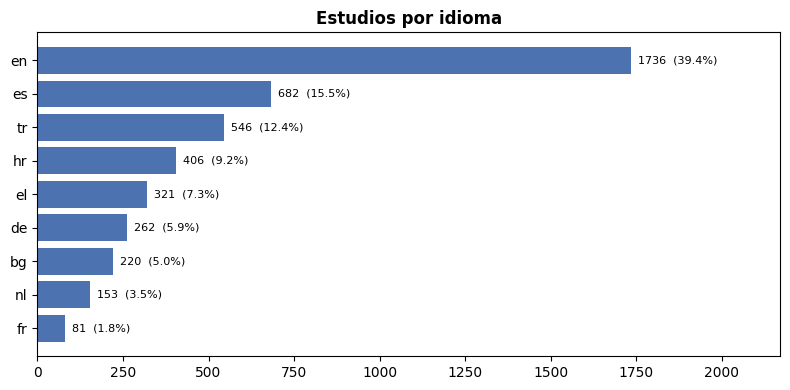

      estudios   pct  gold
lang                      
en        1736  39.4    28
es         682  15.5    10
tr         546  12.4     6
hr         406   9.2     4
el         321   7.3     3
de         262   5.9     2
bg         220   5.0     3
nl         153   3.5     2
fr          81   1.8     0


In [5]:
# Distribucion de estudios y de etiquetas gold por idioma
lc = master['lang'].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(lc.index[::-1], lc.values[::-1], color='#4C72B0')
for i, v in enumerate(lc.values[::-1]):
    ax.text(v + 20, i, f'{v}  ({v/len(master)*100:.1f}%)', va='center', fontsize=8)
ax.set_xlim(0, lc.max() * 1.25); ax.set_title('Estudios por idioma', fontweight='bold')
plt.tight_layout(); plt.savefig(f"{CFG['out']}/eda1_idiomas.png", dpi=120); plt.show()

eda_lang = pd.DataFrame({'estudios': lc, 'pct': (lc / len(master) * 100).round(1),
                         'gold': gold_master['lang'].value_counts().reindex(lc.index).fillna(0).astype(int)})
print(eda_lang.to_string())

## EDA 2 — Longitud de los informes

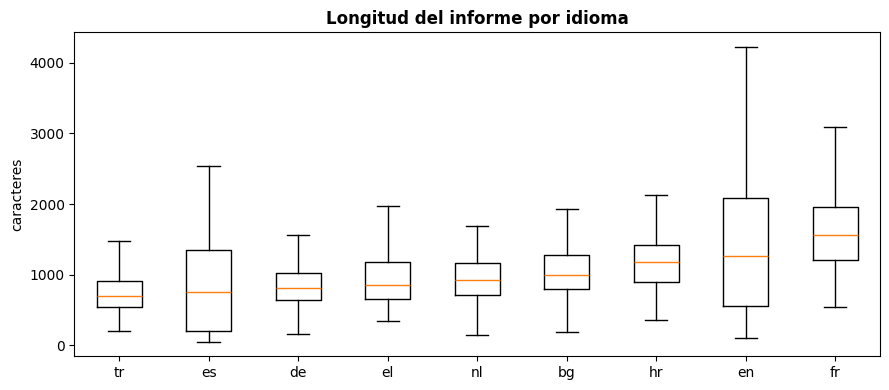

      count  median  min   max
lang                          
tr      546   692.0  205  2056
es      682   752.0   52  3247
de      262   807.0  162  1790
el      321   858.0  347  3146
nl      153   918.0  143  1854
bg      220   999.0  191  2889
hr      406  1172.0  361  2424
en     1736  1270.0  106  4743
fr       81  1560.0  539  4523


In [6]:
# Longitud del informe por idioma
orden = master.groupby('lang')['rep_len'].median().sort_values().index.tolist()
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([master.loc[master['lang'] == l, 'rep_len'].values for l in orden], tick_labels=orden, showfliers=False)
ax.set_ylabel('caracteres'); ax.set_title('Longitud del informe por idioma', fontweight='bold')
plt.tight_layout(); plt.savefig(f"{CFG['out']}/eda2_longitud.png", dpi=120); plt.show()
print(master.groupby('lang')['rep_len'].agg(['count', 'median', 'min', 'max']).sort_values('median').round(0).to_string())

## EDA 3 — Estructura de los informes: secciones presentes por idioma

/tmp/ipykernel_49/3389542885.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  sec = master.assign(tiene_hallazgos=master['Report'].str.contains(SECTION_RE),
/tmp/ipykernel_49/3389542885.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  tiene_antecedentes=master['Report'].str.contains(HIST_RE))


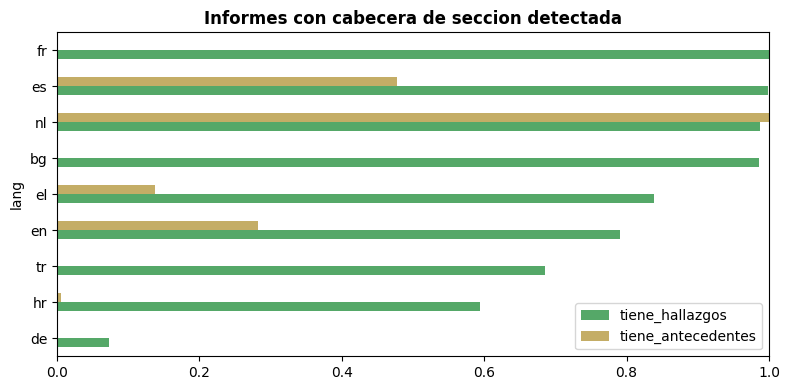

      tiene_hallazgos  tiene_antecedentes
lang                                     
de              0.073               0.000
hr              0.594               0.005
tr              0.685               0.000
en              0.790               0.282
el              0.838               0.137
bg              0.986               0.000
nl              0.987               1.000
es              0.999               0.478
fr              1.000               0.000


In [7]:
# Porcentaje de informes con cabecera de hallazgos/impresion y con cabecera de antecedentes, por idioma.
# Si un idioma no tiene cabeceras, el recorte de seccion del extractor no puede aplicarse
SECTION_RE = re.compile(
    r'(findings|impression|conclusion|hallazgos|impresi[oó]n|conclusi[oó]n|bulgular|sonu[cç]|'
    r'nalaz|zaklju|ευρήματα|εντύπωση|bevindingen|conclusie|befund|beurteilung|заключение|находки|'
    r'résultats|conclusion|заключение|резултати|извод)', re.IGNORECASE)
HIST_RE = re.compile(
    r'(clinical history|indication|antecedentes|indicaci[oó]n|klinik|anamnez|anamnesis|'
    r'ιστορικό|κλινικ|klinische|anamnese|indication|анамнеза|клинич)', re.IGNORECASE)

sec = master.assign(tiene_hallazgos=master['Report'].str.contains(SECTION_RE),
                    tiene_antecedentes=master['Report'].str.contains(HIST_RE))
sec_tab = sec.groupby('lang')[['tiene_hallazgos', 'tiene_antecedentes']].mean().sort_values('tiene_hallazgos')
fig, ax = plt.subplots(figsize=(8, 4))
sec_tab.plot.barh(ax=ax, color=['#55A868', '#C4AD66'])
ax.set_xlim(0, 1); ax.set_title('Informes con cabecera de seccion detectada', fontweight='bold')
plt.tight_layout(); plt.savefig(f"{CFG['out']}/eda3_secciones.png", dpi=120); plt.show()
print(sec_tab.round(3).to_string())

## EDA 4 — Prevalencia de los 12 hallazgos

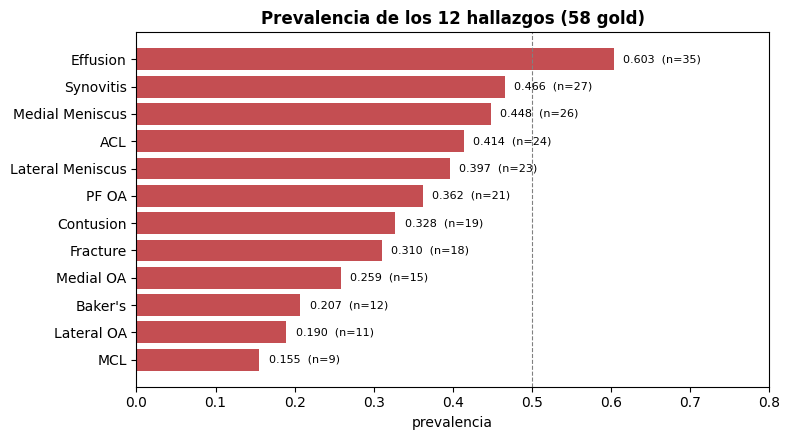

Positivos por hallazgo: {'MCL': 9, 'Lateral OA': 11, "Baker's": 12, 'Medial OA': 15, 'Fracture': 18, 'Contusion': 19, 'PF OA': 21, 'Lateral Meniscus': 23, 'ACL': 24, 'Medial Meniscus': 26, 'Synovitis': 27, 'Effusion': 35}
Hallazgos por estudio  : min 1 | mediana 4 | max 9
Estudios gold sin ningun hallazgo: 0


In [8]:
# Prevalencia de cada hallazgo en los 58 gold, el unico conjunto con verdad verificada
pg = PREV_GOLD.sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(pg.index, pg.values, color='#C44E52'); ax.axvline(0.5, ls='--', c='gray', lw=.8)
for i, v in enumerate(pg.values):
    ax.text(v + 0.012, i, f'{v:.3f}  (n={int(round(v*len(gold_master)))})', va='center', fontsize=8)
ax.set_xlim(0, 0.8); ax.set_xlabel('prevalencia'); ax.set_title('Prevalencia de los 12 hallazgos (58 gold)', fontweight='bold')
plt.tight_layout(); plt.savefig(f"{CFG['out']}/eda4_prevalencia.png", dpi=120); plt.show()

n_hall = gold_master[LABELS].sum(axis=1)
print('Positivos por hallazgo:', gold_master[LABELS].sum().astype(int).sort_values().to_dict())
print('Hallazgos por estudio  : min', int(n_hall.min()), '| mediana', int(n_hall.median()), '| max', int(n_hall.max()))
print('Estudios gold sin ningun hallazgo:', int((n_hall == 0).sum()))

## EDA 5 — Co-ocurrencia de hallazgos

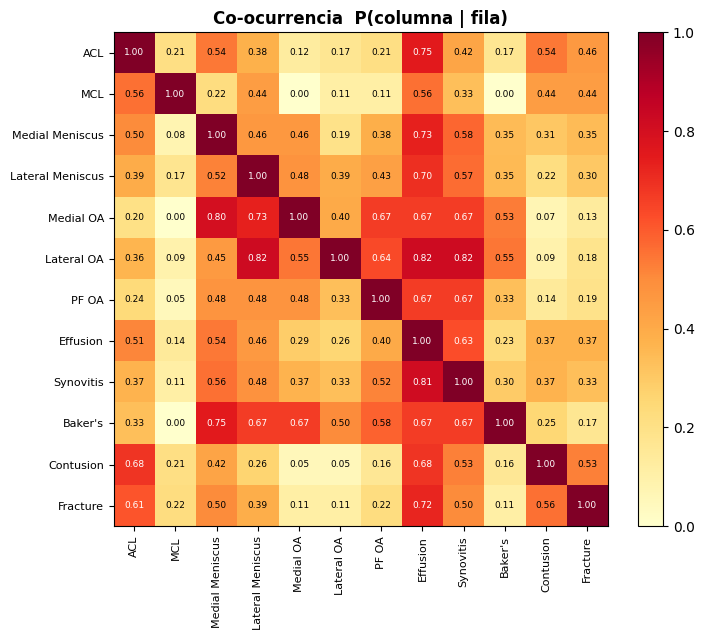

Par mas asociado: P(Lateral Meniscus | Lateral OA) = 0.82


In [9]:
# P(columna | fila) en los 58 gold: que lesiones aparecen juntas
G = gold_master[LABELS].values
co = (G.T @ G) / np.maximum(G.sum(0)[:, None], 1)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(co, cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(12)); ax.set_xticklabels(LABELS, rotation=90, fontsize=8)
ax.set_yticks(range(12)); ax.set_yticklabels(LABELS, fontsize=8)
for i in range(12):
    for j in range(12):
        ax.text(j, i, f'{co[i,j]:.2f}', ha='center', va='center', fontsize=6.5, color='white' if co[i, j] > .6 else 'black')
ax.set_title('Co-ocurrencia  P(columna | fila)', fontweight='bold'); plt.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.savefig(f"{CFG['out']}/eda5_coocurrencia.png", dpi=120); plt.show()

off = co.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f'Par mas asociado: P({LABELS[j]} | {LABELS[i]}) = {off[i, j]:.2f}')

## EDA 6 — Heterogeneidad de la imagen entre centros

  0%|          | 0/200 [00:00<?, ?it/s]

Fabricantes: {'SIEMENS': 86, 'PHILIPS': 68, 'GE': 38, 'TOSHIBA': 4, 'GEHC': 2, 'FUJIFILM': 2}

     campo_T   filas  grosor_mm  pixel_mm  intensidad_max
min     1.16   192.0        0.8      0.14           250.0
50%     1.50   512.0        3.0      0.33           799.0
max     3.00  1024.0        4.0      0.89          9064.0

Intensidad maxima por idioma (mediana):
lang
nl     503.0
hr     513.0
el     699.5
bg     725.5
es     802.5
en     819.0
fr     993.0
tr    1689.0
de    1738.5


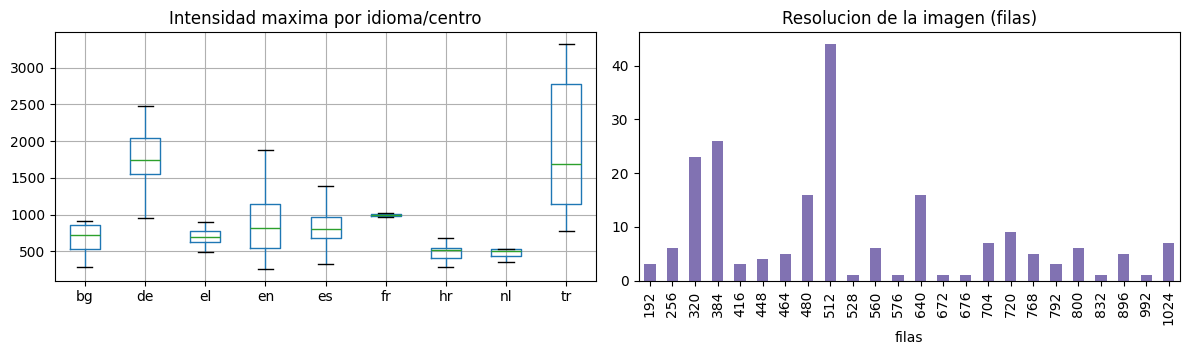

In [10]:
# Metadatos DICOM de una muestra de estudios
import pydicom

def dicom_info(path):
    fs = sorted(f for f in os.listdir(path) if f.endswith('.dcm'))
    d = pydicom.dcmread(os.path.join(path, fs[len(fs) // 2]))
    a = d.pixel_array
    return {'fabricante': str(getattr(d, 'Manufacturer', 'NA')).split()[0].upper()[:12],
            'campo_T': float(getattr(d, 'MagneticFieldStrength', np.nan) or np.nan),
            'filas': int(a.shape[0]), 'grosor_mm': float(getattr(d, 'SliceThickness', np.nan) or np.nan),
            'pixel_mm': float(getattr(d, 'PixelSpacing', [np.nan])[0]), 'intensidad_max': int(a.max())}

muestra = master.sample(200, random_state=SEED)
info = pd.DataFrame([{**dicom_info(r['sag_path']), 'lang': r['lang']} for _, r in tqdm(muestra.iterrows(), total=len(muestra))])

print('Fabricantes:', info['fabricante'].value_counts().to_dict())
print()
print(info[['campo_T', 'filas', 'grosor_mm', 'pixel_mm', 'intensidad_max']].describe().loc[['min', '50%', 'max']].round(2).to_string())
print()
print('Intensidad maxima por idioma (mediana):')
print(info.groupby('lang')['intensidad_max'].median().sort_values().to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
info.boxplot(column='intensidad_max', by='lang', ax=ax[0], showfliers=False)
ax[0].set_title('Intensidad maxima por idioma/centro'); ax[0].set_xlabel('')
info['filas'].value_counts().sort_index().plot.bar(ax=ax[1], color='#8172B2')
ax[1].set_title('Resolucion de la imagen (filas)')
plt.suptitle(''); plt.tight_layout(); plt.savefig(f"{CFG['out']}/eda6_imagen.png", dpi=120); plt.show()

## EDA 7 calidad, plantillas y fuga

In [11]:
# Integridad de los datos, informes duplicados (plantillas) y fuga entre gold y no-gold
dup = master[master['Report'].duplicated(keep=False)]
g = dup.groupby('Report')['has_gold'].agg(['size', 'sum'])
leak_reports = set(g[(g['sum'] > 0) & (g['sum'] < g['size'])].index)
master['excluir'] = master['Report'].isin(leak_reports) & (~master['has_gold'])

tpl = master['Report'].value_counts(); tpl = tpl[tpl >= 5]
aud = pd.Series({
    'estudios': len(master),
    'informes nulos': int(master['Report'].isna().sum()),
    'StudyInstanceUID duplicados': int(master['StudyInstanceUID'].duplicated().sum()),
    'informes duplicados exactos': int(master['Report'].duplicated().sum()),
    'plantillas (>=5 repeticiones)': len(tpl),
    'estudios con plantilla': int(tpl.sum()),
    'grupos con fuga gold/no-gold': len(leak_reports),
    'estudios excluidos por fuga': int(master['excluir'].sum()),
    'series sagitales de respaldo': int(master['sag_tier'].sum()),
    'series coronales de respaldo': int(master['cor_tier'].sum()),
})
print(aud.to_string())
print('\nPlantillas por idioma:', master[master['Report'].isin(tpl.index)]['lang'].value_counts().to_dict())
print('Plantilla mas repetida (%d estudios):' % tpl.iloc[0], repr(tpl.index[0][:200]))
aud.to_csv(f"{CFG['out']}/eda7_auditoria.csv")

estudios                         4407
informes nulos                      0
StudyInstanceUID duplicados         0
informes duplicados exactos       131
plantillas (>=5 repeticiones)       8
estudios con plantilla             89
grupos con fuga gold/no-gold        1
estudios excluidos por fuga         1
series sagitales de respaldo      257
series coronales de respaldo      159

Plantillas por idioma: {'es': 41, 'tr': 37, 'en': 11}
Plantilla mas repetida (37 estudios): 'Diz eklemi içi sıvı miktarı normal. Çapraz ve yan bağlar normal. Medyal ve lateral menisküs normal. Eklem kıkırdakları ve kemikler normal. Ekstensör mekanizma korunmuş. Proksimal tibyofibular eklem no'


### Hallazgos del EDA
- Varios idiomas tienen muy pocos estudios gold.
- Los 58 estudios gold **no contienen rodillas sin hallazgos**: el conjunto de validación está enriquecido en patología.
- La intensidad y la resolución varían mucho entre centros, lo que obliga a normalizar cada corte por separado.
- Hay informes plantilla y un caso de fuga gold/no-gold, que se excluye del entrenamiento.

# Entregable 1 — Pipeline de extracción de etiquetas débiles

Método basado en **embeddings multilingües + reglas/palabras clave**, tal como permite el PDF:
1. **Recorte de sección**: desde *Hallazgos/Impresión* en adelante.
2. **Segmentación** en oraciones normalizando los saltos de línea.
3. **Localización** de la frase relevante por similitud de embeddings multilingües.
4. **Compuerta de entidad**: la frase debe nombrar la estructura anatómica.
5. **Traducción local** (NLLB-200) al inglés y **polaridad por léxico** propio de cada hallazgo (la negación domina).
6. **Etiqueta blanda** en [0, 1]: "no mencionado" no es 0, porque los informes sub-reportan hallazgos.
7. **Calibración** por desplazamiento en el logit para igualar la prevalencia gold.

In [12]:
# Modelos del extractor: embeddings multilingues para localizar y NLLB para traducir al ingles
from sentence_transformers import SentenceTransformer, util
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

embed_model = SentenceTransformer(CFG['embed_model'], device=DEVICE)
nllb_tok = AutoTokenizer.from_pretrained(CFG['nllb_model'])
nllb = AutoModelForSeq2SeqLM.from_pretrained(CFG['nllb_model']).to(DEVICE).eval()
LANG_MAP = {'en': 'eng_Latn', 'es': 'spa_Latn', 'tr': 'tur_Latn', 'hr': 'hrv_Latn', 'el': 'ell_Grek',
            'bg': 'bul_Cyrl', 'nl': 'nld_Latn', 'fr': 'fra_Latn', 'de': 'deu_Latn'}
print('Cobertura de idiomas:', round(master['lang'].isin(LANG_MAP).mean() * 100, 1), '%')

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (18 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Cobertura de idiomas: 100.0 %


In [13]:
# Extractor: localizacion por embeddings, compuerta de entidad, traduccion, polaridad y fallback atenuado
NEG_RE = re.compile(r'\b(no |not |without|intact|normal|unremarkable|negative for|preserved|within normal|'
                    r'free of|absence of|absent|spared|no evidence)\b', re.IGNORECASE)
POS_TERMS = {
    'ACL': r'tear|torn|rupt|sprain|disrupt|discontinu|lax',
    'MCL': r'tear|torn|rupt|sprain|disrupt|discontinu',
    'Medial Meniscus': r'tear|torn|rupt|macerat|displac|fragment',
    'Lateral Meniscus': r'tear|torn|rupt|macerat|displac|fragment',
    'Medial OA': r'osteoarthritis|arthros|chondropathy|chondral|cartilage loss|cartilage defect|ulcer|osteophyt|degenerat',
    'Lateral OA': r'osteoarthritis|arthros|chondropathy|chondral|cartilage loss|cartilage defect|ulcer|osteophyt|degenerat',
    'PF OA': r'osteoarthritis|arthros|chondropathy|chondral|cartilage loss|cartilage defect|ulcer|osteophyt|degenerat',
    'Effusion': r'effusion|joint fluid|fluid collection|fluid in the joint',
    'Synovitis': r'synovitis|synovial thickening|synovial proliferation|synovial enhancement',
    "Baker's": r'cyst',
    'Contusion': r'contusion|marrow edema|marrow oedema|bone edema|bone oedema|bruise',
    'Fracture': r'fractur',
}
ENT_GATE = {
    'ACL': r'anterior cruciate|\bACL\b|cruciate ligament',
    'MCL': r'medial collateral|\bMCL\b|collateral ligament',
    'Medial Meniscus': r'medial menisc|menisci|meniscal',
    'Lateral Meniscus': r'lateral menisc|menisci|meniscal',
    'Medial OA': r'medial (compartment|femorotibial|condyl|tibial|joint)|medial.{0,20}cartilage',
    'Lateral OA': r'lateral (compartment|femorotibial|condyl|tibial|joint)|lateral.{0,20}cartilage',
    'PF OA': r'patell|trochle|femoropatell|retropatell',
    'Effusion': r'effusion|joint fluid|intra-?articular fluid',
    'Synovitis': r'synovi',
    "Baker's": r'baker|popliteal|cyst',
    'Contusion': r'marrow|contusion|bruise|bone signal',
    'Fracture': r'fractur|avulsi',
}
ENTITIES = {
    'ACL': 'anterior cruciate ligament ACL ligamento cruzado anterior LCA',
    'MCL': 'medial collateral ligament MCL ligamento colateral medial LCM',
    'Medial Meniscus': 'medial meniscus menisco medial',
    'Lateral Meniscus': 'lateral meniscus menisco lateral',
    'Medial OA': 'medial compartment cartilage femorotibial medial condropatia compartimento medial',
    'Lateral OA': 'lateral compartment cartilage femorotibial lateral condropatia compartimento lateral',
    'PF OA': 'patellofemoral patella trochlea cartilage rotula troclea',
    'Effusion': 'joint effusion derrame articular',
    'Synovitis': 'synovitis synovial membrane sinovitis',
    "Baker's": 'Baker cyst popliteal cyst quiste popliteo',
    'Contusion': 'bone marrow edema bone contusion edema oseo medula',
    'Fracture': 'fracture fractura',
}
POS_RE = {k: re.compile(v, re.IGNORECASE) for k, v in POS_TERMS.items()}
GATE_RE = {k: re.compile(v, re.IGNORECASE) for k, v in ENT_GATE.items()}
ENT_EMB = {k: embed_model.encode([v], convert_to_tensor=True) for k, v in ENTITIES.items()}
S_POS, S_AMBIG, S_NEG, S_NOMENTION = 0.95, 0.45, 0.08, CFG['p_prior']

def findings_section(t):
    m = SECTION_RE.search(t)
    return t[m.start():] if m else t

def split_sentences(t):
    norm = re.sub(r'\s+', ' ', t)
    return [p.strip() for p in re.split(r'(?<=[a-záéíóúñ0-9])[.;]\s+', norm) if len(p.strip()) > 15]

@torch.no_grad()
def translate_batch(sents, lang):
    if lang == 'en' or not sents:
        return {s: s for s in sents}
    nllb_tok.src_lang = LANG_MAP.get(lang, 'eng_Latn')
    inp = nllb_tok(sents, return_tensors='pt', truncation=True, max_length=150, padding=True).to(DEVICE)
    out = nllb.generate(**inp, max_length=150, forced_bos_token_id=nllb_tok.convert_tokens_to_ids('eng_Latn'))
    return dict(zip(sents, nllb_tok.batch_decode(out, skip_special_tokens=True)))

def sentence_score(s, f):
    if NEG_RE.search(s): return S_NEG
    if POS_RE[f].search(s): return S_POS
    return S_AMBIG

def extract(report, lang, top_k=CFG['top_k'], min_sim=CFG['min_sim']):
    sents = split_sentences(findings_section(report))
    if not sents:
        return {f: S_NOMENTION for f in LABELS}, {f: False for f in LABELS}
    emb = embed_model.encode(sents, convert_to_tensor=True)
    cands, pool_s = {}, set()
    for f in LABELS:
        sims = util.cos_sim(emb, ENT_EMB[f]).squeeze(1)
        vals, idxs = sims.topk(min(top_k, len(sents)))
        c = [(sents[i], v) for v, i in zip(vals.tolist(), idxs.tolist()) if v >= min_sim]
        cands[f] = c; pool_s.update(s for s, _ in c)
    trans = translate_batch(list(pool_s), lang)
    sc, mn = {}, {}
    for f, cs in cands.items():
        if not cs:
            sc[f], mn[f] = S_NOMENTION, False; continue
        gated = [(s, w) for s, w in cs if GATE_RE[f].search(trans[s])]
        if gated:
            sc[f] = sum(w * sentence_score(trans[s], f) for s, w in gated) / sum(w for _, w in gated); mn[f] = True
        else:
            raw = sum(w * sentence_score(trans[s], f) for s, w in cs) / sum(w for _, w in cs)
            sc[f], mn[f] = 0.5 * raw + 0.5 * S_NOMENTION, False
    return sc, mn

print('Extractor listo')

Extractor listo


## 1.1 Validación contra los 58 estudios gold

In [14]:
# AUC del score continuo (sin umbral) contra las etiquetas doradas, separacion y tasa de mencion
from sklearn.metrics import roc_auc_score

rs, rm = [], []
for _, r in tqdm(gold_master.iterrows(), total=len(gold_master)):
    s, m = extract(r['Report'], r['lang']); rs.append(s); rm.append(m)
S_gold, M_gold = pd.DataFrame(rs), pd.DataFrame(rm)

e1 = pd.DataFrame([{'hallazgo': f, 'prev': gold_master[f].mean(), 'n_pos': int(gold_master[f].sum()),
                    'AUC': roc_auc_score(gold_master[f].values, S_gold[f].values),
                    'score_pos': S_gold.loc[gold_master[f] == 1, f].mean(),
                    'score_neg': S_gold.loc[gold_master[f] == 0, f].mean(),
                    'mencion': M_gold[f].mean()} for f in LABELS])
e1['separacion'] = e1['score_pos'] - e1['score_neg']
e1.to_csv(f"{CFG['out']}/e1_auc_extractor.csv", index=False)
display(e1.round(3).sort_values('AUC', ascending=False))
print('AUC macro del extractor:', round(e1['AUC'].mean(), 3), '| separacion media:', round(e1['separacion'].mean(), 3))

  0%|          | 0/58 [00:00<?, ?it/s]

,hallazgo,prev,n_pos,AUC,score_pos,score_neg,mencion,separacion
9,Baker's,0.207,12,0.852,0.740,0.363,0.345,0.377
2,Medial Meniscus,0.448,26,0.850,0.747,0.338,0.552,0.409
1,MCL,0.155,9,0.813,0.612,0.322,0.569,0.290
4,Medial OA,0.259,15,0.774,0.518,0.332,0.293,0.186
3,Lateral Meniscus,0.397,23,0.771,0.667,0.353,0.500,0.314
6,PF OA,0.362,21,0.731,0.516,0.343,0.534,0.173
0,ACL,0.414,24,0.705,0.588,0.378,0.466,0.210
11,Fracture,0.310,18,0.641,0.613,0.360,0.379,0.253
8,Synovitis,0.466,27,0.606,0.448,0.368,0.155,0.080
5,Lateral OA,0.190,11,0.603,0.512,0.346,0.259,0.166


AUC macro del extractor: 0.706 | separacion media: 0.216


## 1.2 Calibración y tasa de acuerdo/ruido (validación cruzada)

In [15]:
# Desplazamiento en el logit por hallazgo; accuracy estimada con 5 folds (se calibra en 4, se evalua en 1)
from scipy.special import logit, expit
from scipy.optimize import brentq
from sklearn.model_selection import StratifiedKFold

def fit_shift(s, target):
    z = logit(np.clip(s, 1e-3, 1 - 1e-3))
    return brentq(lambda b: expit(z + b).mean() - target, -12, 12)

def apply_shift(s, b):
    return expit(logit(np.clip(s, 1e-3, 1 - 1e-3)) + b)

rows = []
for f in LABELS:
    y, s = gold_master[f].values.astype(int), S_gold[f].values
    acc = []
    for tr, te in StratifiedKFold(CFG['n_folds'], shuffle=True, random_state=SEED).split(s, y):
        b = fit_shift(s[tr], y[tr].mean())
        acc.append(((apply_shift(s[te], b) >= .5).astype(int) == y[te]).mean())
    rows.append({'hallazgo': f, 'acc_cv': np.mean(acc), 'baseline': max(y.mean(), 1 - y.mean())})
ruido = pd.DataFrame(rows)
ruido['mejora'] = ruido['acc_cv'] - ruido['baseline']
ruido['tasa_ruido'] = 1 - ruido['acc_cv']
ruido = ruido.merge(e1[['hallazgo', 'AUC']], on='hallazgo')
ruido.to_csv(f"{CFG['out']}/e1_tasa_ruido.csv", index=False)
display(ruido.round(3))
print('Accuracy CV macro :', round(ruido['acc_cv'].mean(), 3), '| baseline trivial:', round(ruido['baseline'].mean(), 3))
print('Tasa de ruido     :', round(ruido['tasa_ruido'].mean(), 3))
print('Hallazgos que superan el baseline:', int((ruido['mejora'] > 0).sum()), '/ 12')

,hallazgo,acc_cv,baseline,mejora,tasa_ruido,AUC
0,ACL,0.673,0.586,0.087,0.327,0.705
1,MCL,0.862,0.845,0.017,0.138,0.813
2,Medial Meniscus,0.761,0.552,0.209,0.239,0.850
3,Lateral Meniscus,0.795,0.603,0.192,0.205,0.771
4,Medial OA,0.811,0.741,0.069,0.189,0.774
5,Lateral OA,0.861,0.810,0.050,0.139,0.603
6,PF OA,0.673,0.638,0.035,0.327,0.731
7,Effusion,0.585,0.603,-0.019,0.415,0.544
8,Synovitis,0.589,0.534,0.055,0.411,0.606
9,Baker's,0.862,0.793,0.069,0.138,0.852


Accuracy CV macro : 0.74 | baseline trivial: 0.672
Tasa de ruido     : 0.26
Hallazgos que superan el baseline: 10 / 12


## 1.3 Etiquetado del pool de entrenamiento

In [16]:
# Extraccion sobre una muestra del pool sin gold (excluida la fuga) y calibracion a la prevalencia gold
pool = (master[(~master['has_gold']) & (~master['excluir'])]
        .sample(n=CFG['pool_size'], random_state=SEED).reset_index(drop=True))
rs, rm = [], []
for _, r in tqdm(pool.iterrows(), total=len(pool)):
    s, m = extract(r['Report'], r['lang']); rs.append(s); rm.append(m)
S_raw, M_pool = pd.DataFrame(rs), pd.DataFrame(rm)

SHIFT = {f: fit_shift(S_raw[f].values, PREV_GOLD[f]) for f in LABELS}
S_cal = pd.DataFrame({f: apply_shift(S_raw[f].values, SHIFT[f]) for f in LABELS})
S_cal['StudyInstanceUID'] = pool['StudyInstanceUID'].values
S_cal.to_parquet(f"{CFG['out']}/pool_etiquetas_blandas.parquet", index=False)

chk = pd.DataFrame({'prev_gold': PREV_GOLD, 'cruda': S_raw.mean(), 'calibrada': S_cal[LABELS].mean(),
                    'mencion': M_pool.mean()})
display(chk.round(3))
assert (chk['calibrada'] / chk['prev_gold']).between(.95, 1.05).all(), 'la calibracion no cuadro'
assert S_cal[LABELS].mean().mean() < .5, 'targets demasiado positivos'
print('Error de prevalencia antes:', round((chk['cruda'] - chk['prev_gold']).abs().mean(), 4),
      '| despues:', round((chk['calibrada'] - chk['prev_gold']).abs().mean(), 4))

  0%|          | 0/1200 [00:00<?, ?it/s]

,prev_gold,cruda,calibrada,mencion
ACL,0.414,0.328,0.414,0.352
MCL,0.155,0.289,0.155,0.524
Medial Meniscus,0.448,0.411,0.448,0.532
Lateral Meniscus,0.397,0.348,0.397,0.480
Medial OA,0.259,0.347,0.259,0.200
Lateral OA,0.190,0.335,0.190,0.220
PF OA,0.362,0.354,0.362,0.454
Effusion,0.603,0.389,0.603,0.221
Synovitis,0.466,0.335,0.466,0.098
Baker's,0.207,0.392,0.207,0.338


Error de prevalencia antes: 0.0909 | despues: 0.0


# Subconjuntos de trabajo

Los 58 gold se reservan **íntegros como validación**. Se construyen tres conjuntos de entrenamiento:
- **Aleatorio 600** (58 + 542) — tamaño recomendado por el PDF, muestreo aleatorio.
- **Estratificado 600** (58 + 542) — estratificación recomendada por el PDF, asegurando positivos en clases raras.
- **Extendido 1200** (58 + 1142) — para medir el efecto del tamaño de datos.

In [17]:
# Construccion de los tres subconjuntos sobre las mismas etiquetas calibradas
N_WEAK = CFG['subset_size'] - len(gold_master)
B = np.zeros((len(pool), len(LABELS)), dtype=int)
for j, f in enumerate(LABELS):
    B[:, j] = (S_cal[f].values >= np.quantile(S_cal[f].values, 1 - PREV_GOLD[f])).astype(int)

def estratificar(B, n, rng):
    objetivo = {j: int(round(PREV_GOLD[LABELS[j]] * n)) for j in range(len(LABELS))}
    elegidos, libres = [], np.ones(len(B), dtype=bool)
    for j in sorted(range(len(LABELS)), key=lambda k: PREV_GOLD[LABELS[k]]):
        faltan = objetivo[j] - (int(B[elegidos, j].sum()) if elegidos else 0)
        if faltan <= 0: continue
        cands = np.where(libres & (B[:, j] == 1))[0]; rng.shuffle(cands)
        toma = cands[:faltan]; elegidos.extend(toma.tolist()); libres[toma] = False
    resto = np.where(libres)[0]; rng.shuffle(resto)
    elegidos.extend(resto[:n - len(elegidos)].tolist())
    return np.array(elegidos[:n])

def construir(idx, nombre):
    weak = pool.iloc[idx].drop(columns=LABELS).copy()
    for f in LABELS:
        weak[f] = S_cal[f].values[idx]
    s = pd.concat([gold_master.assign(split='val_gold'), weak.assign(split='train_weak')], ignore_index=True)
    s.to_parquet(f"{CFG['out']}/subset_{nombre}.parquet", index=False)
    return s

idx_rand  = np.random.default_rng(SEED).choice(len(pool), N_WEAK, replace=False)
idx_strat = estratificar(B, N_WEAK, np.random.default_rng(SEED))
idx_ext   = np.random.default_rng(SEED + 1).choice(len(pool), CFG['subset_ext'] - len(gold_master), replace=False)

sub_rand, sub_strat, sub_ext = construir(idx_rand, 'aleatorio'), construir(idx_strat, 'estratificado'), construir(idx_ext, 'extendido')

tw = lambda s: s[s['split'] == 'train_weak']
cmp = pd.DataFrame({'prev_gold': PREV_GOLD, 'aleatorio': tw(sub_rand)[LABELS].mean(),
                    'estratificado': tw(sub_strat)[LABELS].mean(), 'extendido': tw(sub_ext)[LABELS].mean(),
                    'pos_aleatorio': B[idx_rand].sum(0), 'pos_estratif': B[idx_strat].sum(0)})
display(cmp.round(3))
for c, sdf in [('aleatorio', sub_rand), ('estratificado', sub_strat), ('extendido', sub_ext)]:
    print(f'{c:14s} train {len(tw(sdf))} | desvio de prevalencia {(cmp[c] - cmp["prev_gold"]).abs().mean():.4f}')

,prev_gold,aleatorio,estratificado,extendido,pos_aleatorio,pos_estratif
ACL,0.414,0.406,0.447,0.415,262,312
MCL,0.155,0.154,0.184,0.156,114,172
Medial Meniscus,0.448,0.442,0.492,0.448,321,366
Lateral Meniscus,0.397,0.406,0.442,0.399,291,341
Medial OA,0.259,0.262,0.299,0.258,148,203
Lateral OA,0.190,0.196,0.225,0.191,126,185
PF OA,0.362,0.366,0.408,0.360,203,259
Effusion,0.603,0.607,0.635,0.603,335,393
Synovitis,0.466,0.463,0.492,0.465,290,359
Baker's,0.207,0.197,0.264,0.209,115,173


aleatorio      train 542 | desvio de prevalencia 0.0052
estratificado  train 542 | desvio de prevalencia 0.0358
extendido      train 1142 | desvio de prevalencia 0.0010


## Caché de volúmenes (dos planos, 32 canales)

  0%|          | 0/1245 [00:00<?, ?it/s]

Volumenes: (1245, 32, 224, 224) | 4.00 GB | estudios: 1245


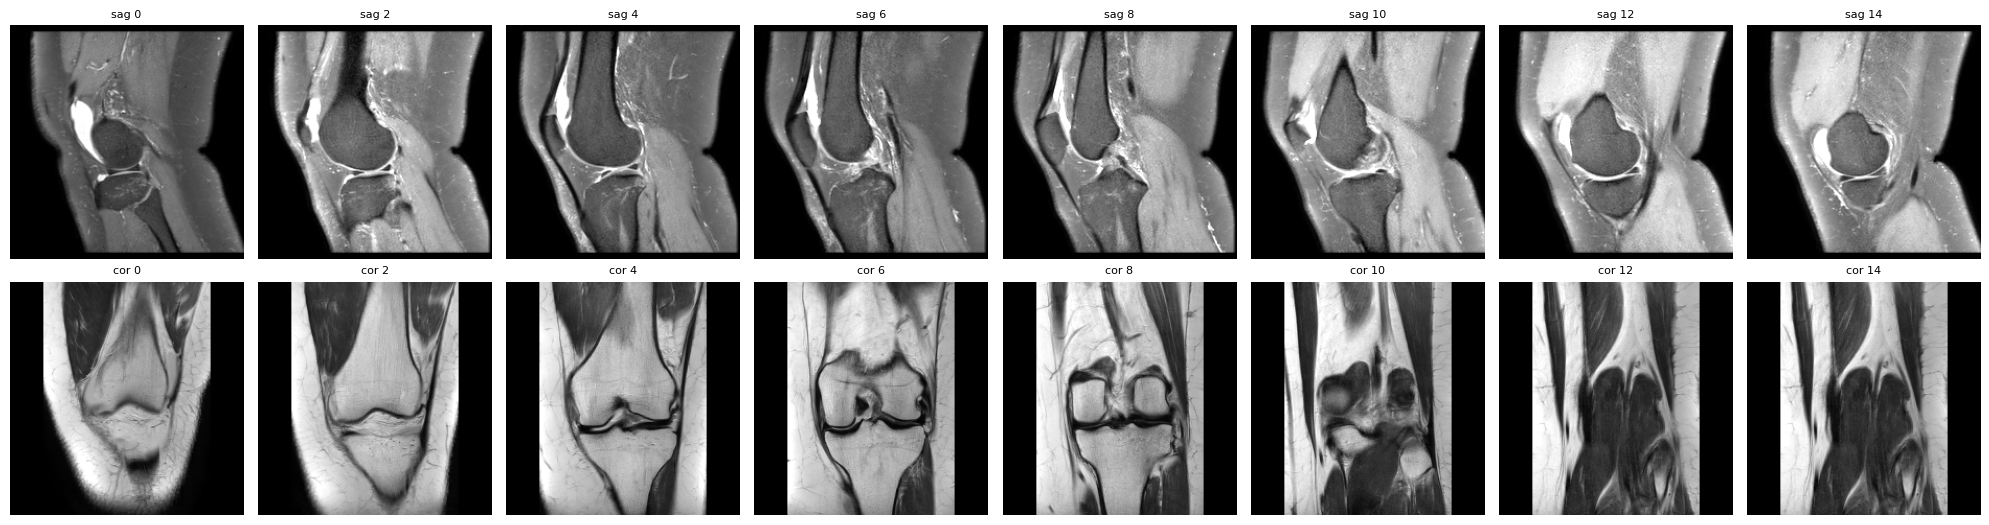

In [18]:
# Se liberan los modelos de texto y se cachean los estudios de los tres subconjuntos: 16 cortes sagitales
# + 16 coronales, ordenados por InstanceNumber, del 25-75% central, normalizados por percentiles 1-99
import cv2

del nllb, embed_model, ENT_EMB
gc.collect(); torch.cuda.empty_cache()

def load_series(path, n=CFG['n_slices'], size=CFG['img_size']):
    metas = []
    for f in os.listdir(path):
        if not f.endswith('.dcm'): continue
        try:
            metas.append((int(getattr(pydicom.dcmread(os.path.join(path, f), stop_before_pixels=True), 'InstanceNumber', 0)), f))
        except Exception:
            continue
    if not metas: return None
    ordered = [f for _, f in sorted(metas)]
    lo = int(len(ordered) * .25); hi = max(int(len(ordered) * .75), lo + 1)
    sl = []
    for i in np.linspace(lo, hi - 1, min(n, hi - lo)).astype(int):
        try:
            a = pydicom.dcmread(os.path.join(path, ordered[i])).pixel_array.astype(np.float32)
        except Exception:
            continue
        a = cv2.resize(a, (size, size), interpolation=cv2.INTER_AREA)
        p1, p99 = np.percentile(a, [1, 99])
        sl.append(np.clip((a - p1) / (p99 - p1 + 1e-6), 0, 1))
    if not sl: return None
    while len(sl) < n: sl.append(sl[-1])
    return np.stack(sl[:n])

cache_df = pd.concat([sub_rand, sub_strat, sub_ext], ignore_index=True).drop_duplicates('StudyInstanceUID').reset_index(drop=True)
vols, keep = [], []
for i, r in tqdm(cache_df.iterrows(), total=len(cache_df)):
    s, c = load_series(r['sag_path']), load_series(r['cor_path'])
    if s is not None and c is not None:
        vols.append(np.concatenate([s, c]).astype(np.float16)); keep.append(i)
VOL = np.stack(vols)
VOL_IDX = {u: k for k, u in enumerate(cache_df.loc[keep, 'StudyInstanceUID'])}
np.save(f"{CFG['out']}/volumenes_2planos.npy", VOL)

assert all(u in VOL_IDX for u in gold_master['StudyInstanceUID']), 'falta algun gold en cache'
print('Volumenes:', VOL.shape, '| %.2f GB' % (VOL.nbytes / 1e9), '| estudios:', len(VOL_IDX))

ej = VOL[VOL_IDX[gold_master['StudyInstanceUID'].iloc[0]]].astype(np.float32)
fig, ax = plt.subplots(2, 8, figsize=(20, 5.4))
for k in range(8):
    ax[0, k].imshow(ej[k * 2], cmap='gray'); ax[0, k].axis('off'); ax[0, k].set_title(f'sag {k*2}', fontsize=8)
    ax[1, k].imshow(ej[16 + k * 2], cmap='gray'); ax[1, k].axis('off'); ax[1, k].set_title(f'cor {k*2}', fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG['out']}/fig_cortes_2planos.png", dpi=110); plt.show()

# Entregable 2 — Dos arquitecturas de clasificación multietiqueta

- **A. CNN 2.5D desde cero**: bloques de doble convolución 3×3 (estilo VGG), BatchNorm y *global average pooling*.
- **B. Transfer learning**: ResNet-50 preentrenada en ImageNet; la primera convolución se adapta de 3 a 32 canales
  promediando los pesos RGB y reescalando por 3/32. Cabeza de **12 salidas sigmoides independientes**.

Entrada: 32 canales (16 cortes sagitales + 16 coronales). Augmentation: solo traslación e intensidad
(el espejo horizontal intercambiaría medial y lateral en el plano coronal).
Ambas se entrenan sobre el **subconjunto extendido** con *focal loss*, que el PDF sugiere para hallazgos raros.

In [19]:
# Dataset con etiquetas blandas y constructor de DataLoaders para cualquier subconjunto
class KneeDS(Dataset):
    def __init__(self, vols, y, augment=False):
        self.v, self.y, self.aug = vols, y.astype(np.float32), augment
    def __len__(self):
        return len(self.v)
    def __getitem__(self, i):
        x = self.v[i].astype(np.float32)
        if self.aug:
            if np.random.rand() > .5:
                x = np.roll(x, np.random.randint(-16, 17, 2), axis=(1, 2))
            if np.random.rand() > .5:
                x = np.clip(x * np.random.uniform(.9, 1.1), 0, 1)
        return torch.from_numpy(x), torch.from_numpy(self.y[i])

def make_loader(subset_df, split, augment, bs=CFG['batch_size']):
    d = subset_df[subset_df['split'] == split]
    idx = np.array([VOL_IDX[u] for u in d['StudyInstanceUID']])
    return DataLoader(KneeDS(VOL[idx], d[LABELS].values, augment), batch_size=bs,
                      shuffle=augment, num_workers=2, pin_memory=True)

dl_va        = make_loader(sub_ext,   'val_gold',   False)
dl_tr_ext    = make_loader(sub_ext,   'train_weak', True)
dl_tr_rand   = make_loader(sub_rand,  'train_weak', True)
dl_tr_strat  = make_loader(sub_strat, 'train_weak', True)

xb, yb = next(iter(dl_tr_ext))
print('train extendido', len(dl_tr_ext.dataset), '| aleatorio', len(dl_tr_rand.dataset),
      '| estratificado', len(dl_tr_strat.dataset), '| val', len(dl_va.dataset))
print('batch', tuple(xb.shape), '| target medio', round(float(yb.mean()), 3))

train extendido 1142 | aleatorio 542 | estratificado 542 | val 58
batch (16, 32, 224, 224) | target medio 0.379


In [20]:
# Arquitectura A (CNN desde cero) y arquitectura B (ResNet-50 ImageNet adaptada a 32 canales)
import torchvision.models as tvm

class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.b = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True),
                               nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True),
                               nn.MaxPool2d(2))
    def forward(self, x): return self.b(x)

class KneeCNN25D(nn.Module):
    def __init__(self, cin=IN_CH, n_cls=12, widths=(32, 64, 128, 256)):
        super().__init__()
        ch = [cin] + list(widths)
        self.features = nn.Sequential(*[ConvBlock(ch[i], ch[i + 1]) for i in range(len(widths))])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(.3), nn.Linear(widths[-1], n_cls))
    def forward(self, x): return self.head(self.features(x))

class KneeTransfer(nn.Module):
    def __init__(self, cin=IN_CH, n_cls=12, pretrained=True, freeze_until=0):
        super().__init__()
        net = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        feat, old = net.fc.in_features, net.conv1
        new = nn.Conv2d(cin, 64, 7, stride=2, padding=3, bias=False)
        if pretrained:
            with torch.no_grad():
                new.weight.copy_(old.weight.mean(1, keepdim=True).repeat(1, cin, 1, 1) * (3.0 / cin))
        net.conv1, net.fc = new, nn.Identity()
        self.backbone, self.head = net, nn.Sequential(nn.Dropout(.3), nn.Linear(feat, n_cls))
        for st in [nn.Sequential(net.conv1, net.bn1), net.layer1, net.layer2, net.layer3, net.layer4][:freeze_until]:
            for p in st.parameters():
                p.requires_grad = False
    def forward(self, x): return self.head(self.backbone(x))

for nombre, m in [('A  CNN desde cero', KneeCNN25D()), ('B  ResNet-50', KneeTransfer())]:
    m = m.to(DEVICE)
    print(f'{nombre:18s} params {sum(p.numel() for p in m.parameters()):>11,} | salida {tuple(m(xb.to(DEVICE)).shape)}')
    del m; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 245MB/s]


A  CNN desde cero  params   1,184,652 | salida (16, 12)
B  ResNet-50       params  23,623,564 | salida (16, 12)


In [21]:
# Perdidas sobre etiquetas blandas, evaluacion por AUC contra los gold y bucle de entrenamiento con AMP
from sklearn.metrics import precision_recall_fscore_support

def bce(lo, y):
    return F.binary_cross_entropy_with_logits(lo, y)

def focal(lo, y, gamma=2.0, alpha=0.25):
    b = F.binary_cross_entropy_with_logits(lo, y, reduction='none')
    p = torch.sigmoid(lo); pt = y * p + (1 - y) * (1 - p)
    return ((y * alpha + (1 - y) * (1 - alpha)) * (1 - pt).pow(gamma) * b).mean()

@torch.no_grad()
def evaluate(model, loader=None):
    loader = loader or dl_va
    model.eval(); P, Y = [], []
    for x, y in loader:
        P.append(torch.sigmoid(model(x.to(DEVICE))).float().cpu().numpy()); Y.append(y.numpy())
    P, Y = np.vstack(P), np.vstack(Y)
    return {c: roc_auc_score(Y[:, i], P[:, i]) for i, c in enumerate(LABELS) if len(np.unique(Y[:, i])) > 1}, P, Y

def train_model(model, loader, epochs=CFG['epochs'], lr=CFG['lr_transfer'], loss_fn=focal, tag='m', verbose=True):
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda')
    hist, best, best_state = [], 0., None
    for ep in range(epochs):
        model.train(); tot = 0.
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.amp.autocast('cuda'):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tot += loss.item()
        sched.step()
        aucs, P, _ = evaluate(model)
        macro = float(np.mean(list(aucs.values())))
        hist.append({'epoch': ep, 'loss': tot / len(loader), 'val_auc': macro, 'pred_pos': float((P >= .5).mean())})
        if macro > best:
            best, best_state = macro, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f'[{tag}] ep {ep:2d} | loss {tot/len(loader):.4f} | AUC {macro:.4f} | pred+ {hist[-1]["pred_pos"]:.2f}')
    model.load_state_dict(best_state)
    h = pd.DataFrame(hist)
    assert h['pred_pos'].iloc[-1] < .95, 'COLAPSO: predice positivo en casi todo'
    return model, h, best

def resumen(h, best):
    return {'auc_mejor': best, 'auc_ult5': h['val_auc'].tail(5).mean()}

print('Funciones listas')

Funciones listas


## 2.1 Entrenamiento — Arquitectura A: CNN desde cero

In [22]:
# CNN desde cero sobre el subconjunto extendido
torch.manual_seed(SEED)
model_A = KneeCNN25D().to(DEVICE)
model_A, hist_A, best_A = train_model(model_A, dl_tr_ext, lr=CFG['lr_scratch'], tag='A-scratch')
aucs_A, probs_A, ys_A = evaluate(model_A)
print('\nArquitectura A:', {k: round(v, 4) for k, v in resumen(hist_A, best_A).items()})

[A-scratch] ep  0 | loss 0.0681 | AUC 0.5130 | pred+ 0.08
[A-scratch] ep  5 | loss 0.0629 | AUC 0.5892 | pred+ 0.08
[A-scratch] ep 10 | loss 0.0623 | AUC 0.5887 | pred+ 0.09
[A-scratch] ep 15 | loss 0.0606 | AUC 0.5518 | pred+ 0.11
[A-scratch] ep 19 | loss 0.0598 | AUC 0.5386 | pred+ 0.11

Arquitectura A: {'auc_mejor': 0.5892, 'auc_ult5': np.float64(0.542)}


## 2.2 Entrenamiento — Arquitectura B: ResNet-50 (transfer learning)

In [23]:
# ResNet-50 ImageNet con fine-tuning completo sobre el subconjunto extendido
torch.manual_seed(SEED)
model_B = KneeTransfer().to(DEVICE)
model_B, hist_B, best_B = train_model(model_B, dl_tr_ext, lr=CFG['lr_transfer'], tag='B-resnet50')
aucs_B, probs_B, ys_B = evaluate(model_B)
print('\nArquitectura B:', {k: round(v, 4) for k, v in resumen(hist_B, best_B).items()})

[B-resnet50] ep  0 | loss 0.0700 | AUC 0.5186 | pred+ 0.08
[B-resnet50] ep  5 | loss 0.0562 | AUC 0.5839 | pred+ 0.13
[B-resnet50] ep 10 | loss 0.0493 | AUC 0.5706 | pred+ 0.18
[B-resnet50] ep 15 | loss 0.0459 | AUC 0.5753 | pred+ 0.20
[B-resnet50] ep 19 | loss 0.0454 | AUC 0.5721 | pred+ 0.19

Arquitectura B: {'auc_mejor': 0.606, 'auc_ult5': np.float64(0.573)}


## 2.3 Comparación de las dos arquitecturas

,A_scratch,B_resnet50,diferencia
Synovitis,0.566,0.768,0.202
MCL,0.488,0.617,0.129
Contusion,0.570,0.641,0.072
PF OA,0.501,0.570,0.069
Medial Meniscus,0.639,0.643,0.004
Medial OA,0.653,0.656,0.003
Fracture,0.544,0.546,0.001
Lateral Meniscus,0.676,0.661,-0.015
Lateral OA,0.573,0.524,-0.048
ACL,0.592,0.523,-0.069


,arquitectura,params,auc_mejor,auc_ult5
0,A CNN desde cero,1184652,0.5892,0.542
1,B ResNet-50,23623564,0.6060,0.573


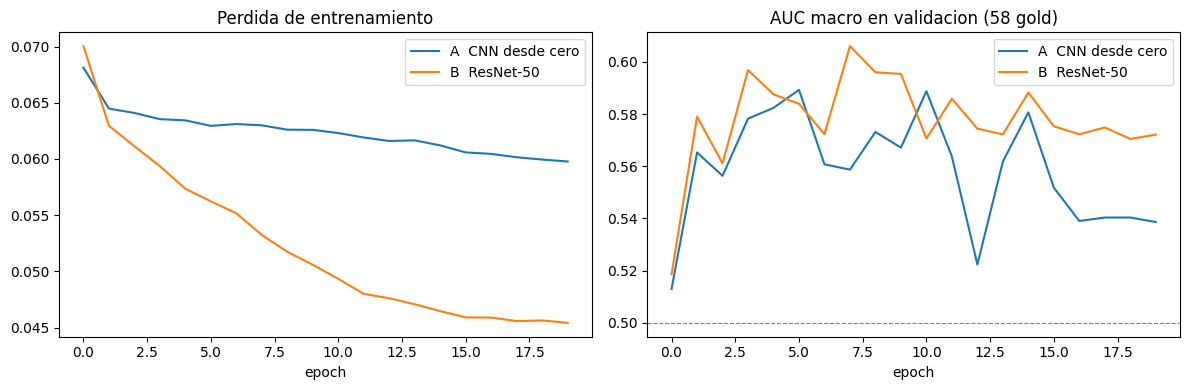

In [24]:
# Comparacion por hallazgo y curvas de entrenamiento
comp = pd.DataFrame({'A_scratch': aucs_A, 'B_resnet50': aucs_B})
comp['diferencia'] = comp['B_resnet50'] - comp['A_scratch']
comp.to_csv(f"{CFG['out']}/e2_comparacion.csv")
display(comp.round(3).sort_values('diferencia', ascending=False))

tabla_arq = pd.DataFrame([
    {'arquitectura': 'A  CNN desde cero', 'params': sum(p.numel() for p in model_A.parameters()), **resumen(hist_A, best_A)},
    {'arquitectura': 'B  ResNet-50',      'params': sum(p.numel() for p in model_B.parameters()), **resumen(hist_B, best_B)}])
display(tabla_arq.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for h, n in [(hist_A, 'A  CNN desde cero'), (hist_B, 'B  ResNet-50')]:
    ax[0].plot(h['epoch'], h['loss'], label=n); ax[1].plot(h['epoch'], h['val_auc'], label=n)
ax[0].set_title('Perdida de entrenamiento'); ax[1].set_title('AUC macro en validacion (58 gold)')
ax[1].axhline(.5, ls='--', c='gray', lw=.8)
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.savefig(f"{CFG['out']}/e2_curvas.png", dpi=110); plt.show()

# Entregable 3 — Evaluación con la métrica oficial

Métrica principal: **AUC-ROC macro** sobre las 12 etiquetas (no depende de umbral).
Precisión, recall y F1 a dos umbrales:
- **0,5**: valor por defecto, asume clases balanceadas.
- **Umbral por prevalencia** (elegido y justificado): por hallazgo, el que iguala la tasa de positivos predichos a la
  prevalencia gold. No se ajusta a los aciertos, por lo que evita el sesgo de optimizar el F1 sobre el propio conjunto de evaluación.

In [25]:
# AUC y precision/recall/F1 para las dos arquitecturas
def tabla_eval(probs, ys, aucs):
    rows = []
    for i, c in enumerate(LABELS):
        y, p = ys[:, i], probs[:, i]
        thr = np.quantile(p, 1 - PREV_GOLD[c])
        m05 = precision_recall_fscore_support(y, (p >= .5).astype(int), average='binary', zero_division=0)
        mpv = precision_recall_fscore_support(y, (p >= thr).astype(int), average='binary', zero_division=0)
        rows.append({'hallazgo': c, 'prev': y.mean(), 'AUC': aucs[c], 'P@0.5': m05[0], 'R@0.5': m05[1], 'F1@0.5': m05[2],
                     'umbral': thr, 'P@prev': mpv[0], 'R@prev': mpv[1], 'F1@prev': mpv[2]})
    return pd.DataFrame(rows).sort_values('AUC', ascending=False)

ev_A, ev_B = tabla_eval(probs_A, ys_A, aucs_A), tabla_eval(probs_B, ys_B, aucs_B)
ev_A.to_csv(f"{CFG['out']}/e3_eval_A.csv", index=False); ev_B.to_csv(f"{CFG['out']}/e3_eval_B.csv", index=False)

print('=== Arquitectura B: ResNet-50 ==='); display(ev_B.round(3))
print('=== Arquitectura A: CNN desde cero ==='); display(ev_A.round(3))

e3 = pd.DataFrame({'A  CNN desde cero': [ev_A['AUC'].mean(), ev_A['F1@0.5'].mean(), ev_A['F1@prev'].mean(), int((ev_A['AUC'] > .5).sum())],
                   'B  ResNet-50':      [ev_B['AUC'].mean(), ev_B['F1@0.5'].mean(), ev_B['F1@prev'].mean(), int((ev_B['AUC'] > .5).sum())]},
                  index=['AUC macro', 'F1 macro @0.5', 'F1 macro @prevalencia', 'hallazgos con AUC > 0.5'])
display(e3.round(3))

=== Arquitectura B: ResNet-50 ===


,hallazgo,prev,AUC,P@0.5,R@0.5,F1@0.5,umbral,P@prev,R@prev,F1@prev
8,Synovitis,0.466,0.768,0.769,0.370,0.500,0.443,0.667,0.667,0.667
7,Effusion,0.603,0.673,0.589,0.943,0.725,0.673,0.714,0.714,0.714
3,Lateral Meniscus,0.397,0.661,0.583,0.304,0.400,0.413,0.478,0.478,0.478
4,Medial OA,0.259,0.656,0.000,0.000,0.000,0.186,0.400,0.400,0.400
2,Medial Meniscus,0.448,0.643,0.647,0.423,0.512,0.428,0.615,0.615,0.615
10,Contusion,0.328,0.641,1.000,0.158,0.273,0.293,0.421,0.421,0.421
1,MCL,0.155,0.617,0.000,0.000,0.000,0.160,0.000,0.000,0.000
6,PF OA,0.362,0.570,0.000,0.000,0.000,0.327,0.381,0.381,0.381
11,Fracture,0.310,0.546,0.000,0.000,0.000,0.229,0.389,0.389,0.389
5,Lateral OA,0.190,0.524,0.000,0.000,0.000,0.130,0.182,0.182,0.182


=== Arquitectura A: CNN desde cero ===


,hallazgo,prev,AUC,P@0.5,R@0.5,F1@0.5,umbral,P@prev,R@prev,F1@prev
7,Effusion,0.603,0.747,0.607,0.971,0.747,0.595,0.714,0.714,0.714
3,Lateral Meniscus,0.397,0.676,0.000,0.000,0.000,0.364,0.522,0.522,0.522
4,Medial OA,0.259,0.653,0.000,0.000,0.000,0.184,0.467,0.467,0.467
2,Medial Meniscus,0.448,0.639,0.000,0.000,0.000,0.405,0.577,0.577,0.577
0,ACL,0.414,0.592,0.000,0.000,0.000,0.395,0.542,0.542,0.542
5,Lateral OA,0.190,0.573,0.000,0.000,0.000,0.154,0.182,0.182,0.182
10,Contusion,0.328,0.570,0.000,0.000,0.000,0.257,0.368,0.368,0.368
8,Synovitis,0.466,0.566,0.000,0.000,0.000,0.404,0.556,0.556,0.556
11,Fracture,0.310,0.544,0.000,0.000,0.000,0.225,0.333,0.333,0.333
9,Baker's,0.207,0.524,0.000,0.000,0.000,0.266,0.333,0.333,0.333


,A CNN desde cero,B ResNet-50
AUC macro,0.589,0.606
F1 macro @0.5,0.062,0.237
F1 macro @prevalencia,0.428,0.406
hallazgos con AUC > 0.5,11.000,11.000


# Entregable 4 — Estudio de ablación

Cuatro factores, cada uno variando una sola cosa respecto a la configuración de referencia
(ResNet-50, focal loss, subconjunto extendido):

| Factor | Comparación |
|---|---|
| Función de pérdida | focal loss vs BCE |
| Estrategia de muestreo | aleatorio vs estratificado (542 estudios) |
| Tamaño de datos | 542 vs 1142 estudios |
| Profundidad entrenable | fine-tuning completo vs feature extraction (backbone congelado) |

Con 58 estudios de validación, diferencias menores a ~0,05 de AUC no son distinguibles del ruido.

In [26]:
# Entrenamiento de las variantes de ablacion (15 epocas cada una)
abl = [{'factor': 'referencia', 'config': 'ResNet-50 | focal | 1142', 'n_train': len(dl_tr_ext.dataset), **resumen(hist_B, best_B)}]

def run(factor, config, loader, loss_fn=focal, freeze=0):
    torch.manual_seed(SEED)
    m = KneeTransfer(freeze_until=freeze).to(DEVICE)
    m, h, best = train_model(m, loader, epochs=CFG['epochs_abl'], loss_fn=loss_fn, tag=config, verbose=False)
    abl.append({'factor': factor, 'config': config, 'n_train': len(loader.dataset), **resumen(h, best)})
    print(f'{config:34s} mejor {best:.4f} | ult5 {h["val_auc"].tail(5).mean():.4f}')
    del m; gc.collect(); torch.cuda.empty_cache()

run('perdida',  'ResNet-50 | BCE | 1142',            dl_tr_ext, loss_fn=bce)
run('muestreo', 'ResNet-50 | focal | 542 aleatorio',  dl_tr_rand)
run('muestreo', 'ResNet-50 | focal | 542 estratif.',  dl_tr_strat)
run('profund.', 'ResNet-50 | focal | 1142 congelado', dl_tr_ext, freeze=5)

abl_df = pd.DataFrame(abl)
abl_df.to_csv(f"{CFG['out']}/e4_ablacion.csv", index=False)
display(abl_df.round(4))
print('Rango (sin feature extraction):', round((lambda v: v.max() - v.min())(abl_df[abl_df['factor'] != 'profund.']['auc_mejor']), 4),
      '| umbral de ruido con n=58: ~0.05')

ResNet-50 | BCE | 1142             mejor 0.6167 | ult5 0.6048
ResNet-50 | focal | 542 aleatorio  mejor 0.5774 | ult5 0.5634
ResNet-50 | focal | 542 estratif.  mejor 0.5848 | ult5 0.5721
ResNet-50 | focal | 1142 congelado mejor 0.5492 | ult5 0.5411


,factor,config,n_train,auc_mejor,auc_ult5
0,referencia,ResNet-50 | focal | 1142,1142,0.6060,0.5730
1,perdida,ResNet-50 | BCE | 1142,1142,0.6167,0.6048
2,muestreo,ResNet-50 | focal | 542 aleatorio,542,0.5774,0.5634
3,muestreo,ResNet-50 | focal | 542 estratif.,542,0.5848,0.5721
4,profund.,ResNet-50 | focal | 1142 congelado,1142,0.5492,0.5411


Rango (sin feature extraction): 0.0393 | umbral de ruido con n=58: ~0.05


# Entregable 5 — Interpretabilidad con Grad-CAM

Mapas de activación de la última capa convolucional de ResNet-50 para los **tres hallazgos de mayor AUC**,
mostrados sobre un corte sagital y uno coronal. La pregunta es si la región resaltada coincide con
la anatomía donde un radiólogo buscaría ese hallazgo.

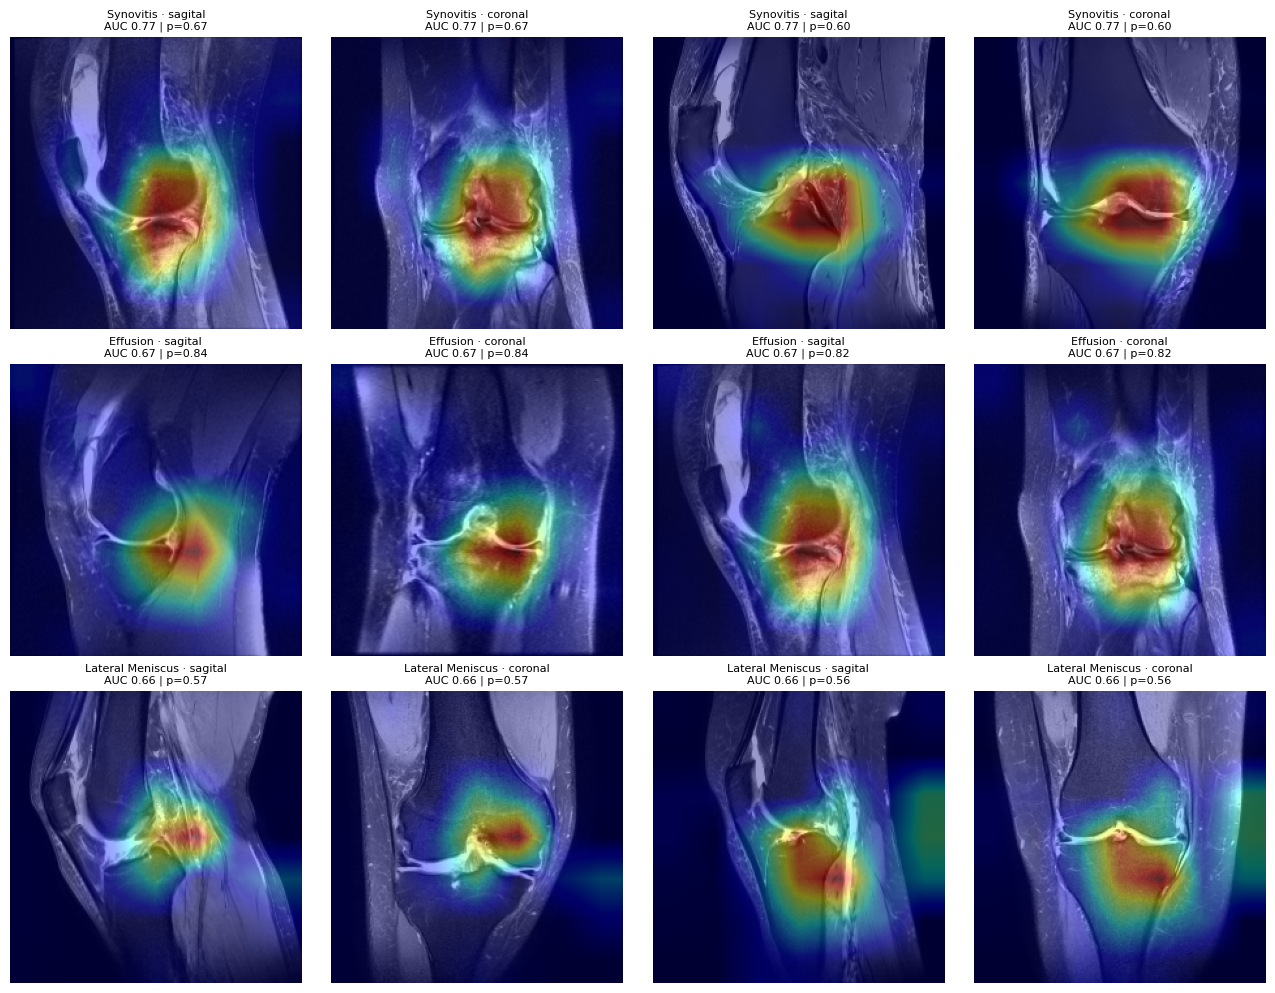

Hallazgos analizados: ['Synovitis', 'Effusion', 'Lateral Meniscus']


In [27]:
# Grad-CAM sobre layer4 (retain_grad, compatible con las ReLU in-place de ResNet)
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.a = model, None
        layer.register_forward_hook(self._fw)
    def _fw(self, m, i, o):
        o.retain_grad(); self.a = o
    def __call__(self, x, cls):
        self.model.eval(); self.model.zero_grad(set_to_none=True)
        self.model(x)[0, cls].backward()
        cam = F.relu((self.a.grad.mean((2, 3), keepdim=True) * self.a).sum(1))[0].detach()
        cam = cam - cam.min()
        return (cam / (cam.max() + 1e-8)).cpu().numpy()

cam_eng = GradCAM(model_B, model_B.backbone.layer4)
top3 = ev_B.head(3)['hallazgo'].tolist()
val_idx = np.array([VOL_IDX[u] for u in sub_ext[sub_ext['split'] == 'val_gold']['StudyInstanceUID']])

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for r, name in enumerate(top3):
    ci = LABELS.index(name)
    pos = np.where(ys_B[:, ci] == 1)[0]
    for c2, idx in enumerate(pos[np.argsort(-probs_B[pos, ci])[:2]]):
        x = torch.from_numpy(VOL[val_idx[idx]].astype(np.float32))[None].to(DEVICE)
        cam = cv2.resize(cam_eng(x, ci), (CFG['img_size'], CFG['img_size']))
        for k, (plano, off) in enumerate([('sagital', 8), ('coronal', 24)]):
            ax = axes[r, c2 * 2 + k]
            ax.imshow(VOL[val_idx[idx]][off].astype(np.float32), cmap='gray'); ax.imshow(cam, cmap='jet', alpha=.4)
            ax.set_title(f'{name} · {plano}\nAUC {aucs_B[name]:.2f} | p={probs_B[idx, ci]:.2f}', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.savefig(f"{CFG['out']}/e5_gradcam.png", dpi=130); plt.show()
print('Hallazgos analizados:', top3)

# Entregable 6 — Análisis del desbalance de clases

Se cuantifica la prevalencia de los 12 hallazgos y se evalúan dos estrategias de mitigación:
1. **Calibración de las etiquetas** por *prior matching* (corrige la prevalencia de los targets).
2. **Focal loss** frente a BCE (pondera los ejemplos difíciles; comparada en el Entregable 4).

,prev_gold,n_pos_gold,prev_cruda,prev_calibrada,auc_modelo,error_antes,error_despues
MCL,0.155,9,0.289,0.155,0.617,0.134,0.0
Lateral OA,0.190,11,0.335,0.190,0.524,0.146,0.0
Baker's,0.207,12,0.392,0.207,0.449,0.185,0.0
Medial OA,0.259,15,0.347,0.259,0.656,0.088,0.0
Fracture,0.310,18,0.308,0.310,0.546,0.003,0.0
Contusion,0.328,19,0.317,0.328,0.641,0.011,0.0
PF OA,0.362,21,0.354,0.362,0.570,0.008,0.0
Lateral Meniscus,0.397,23,0.348,0.397,0.661,0.048,0.0
ACL,0.414,24,0.328,0.414,0.523,0.085,0.0
Medial Meniscus,0.448,26,0.411,0.448,0.643,0.037,0.0


Calibracion  -> error de prevalencia 0.0909 -> 0.0
Focal vs BCE -> AUC 0.606 vs 0.6167
Correlacion prevalencia - AUC del modelo: 0.538


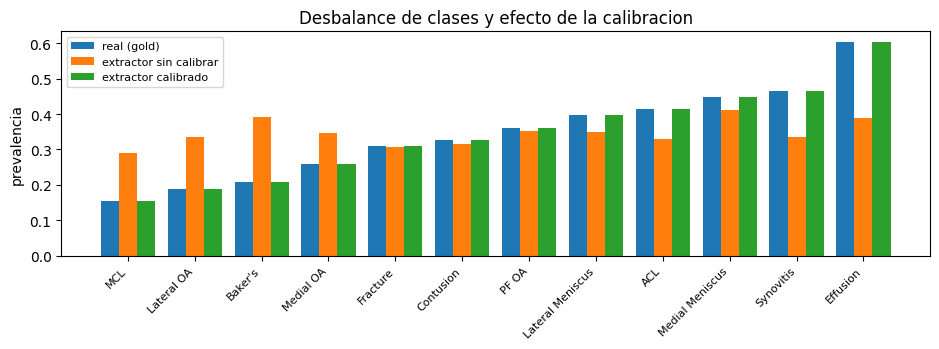

In [28]:
# Prevalencia, positivos disponibles, efecto de la calibracion y relacion prevalencia-AUC
desb = pd.DataFrame({'prev_gold': PREV_GOLD, 'n_pos_gold': gold_master[LABELS].sum().astype(int),
                     'prev_cruda': S_raw.mean(), 'prev_calibrada': S_cal[LABELS].mean(),
                     'auc_modelo': pd.Series(aucs_B)}).sort_values('prev_gold')
desb['error_antes'] = (desb['prev_cruda'] - desb['prev_gold']).abs()
desb['error_despues'] = (desb['prev_calibrada'] - desb['prev_gold']).abs()
desb.to_csv(f"{CFG['out']}/e6_desbalance.csv")
display(desb.round(3))

foc = abl_df.loc[abl_df['config'] == 'ResNet-50 | focal | 1142', 'auc_mejor'].iloc[0]
bce_ = abl_df.loc[abl_df['config'] == 'ResNet-50 | BCE | 1142', 'auc_mejor'].iloc[0]
print('Calibracion  -> error de prevalencia', round(desb['error_antes'].mean(), 4), '->', round(desb['error_despues'].mean(), 4))
print('Focal vs BCE -> AUC', round(foc, 4), 'vs', round(bce_, 4))
print('Correlacion prevalencia - AUC del modelo:', round(desb['prev_gold'].corr(desb['auc_modelo']), 3))

fig, ax = plt.subplots(figsize=(9.5, 3.6))
x = np.arange(len(desb))
ax.bar(x - .27, desb['prev_gold'], .27, label='real (gold)')
ax.bar(x, desb['prev_cruda'], .27, label='extractor sin calibrar')
ax.bar(x + .27, desb['prev_calibrada'], .27, label='extractor calibrado')
ax.set_xticks(x); ax.set_xticklabels(desb.index, rotation=45, ha='right', fontsize=8)
ax.set_ylabel('prevalencia'); ax.legend(fontsize=8); ax.set_title('Desbalance de clases y efecto de la calibracion')
plt.tight_layout(); plt.savefig(f"{CFG['out']}/e6_desbalance.png", dpi=110); plt.show()

# Entregable 7 — Sesgo geográfico y lingüístico

Calidad del extractor por idioma. Además de la tasa de mención se mide la **informatividad** de las etiquetas
(distancia media del score al prior): un idioma con informatividad baja produce etiquetas casi constantes
que apenas aportan señal de aprendizaje, aunque su prevalencia calibrada parezca normal.

/tmp/ipykernel_49/318819763.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  lp['tiene_hallazgos'] = lp['Report'].str.contains(SECTION_RE)


,n,mencion,informatividad,con_seccion,longitud,gold
lang,,,,,,
en,439,0.554,0.218,0.779,1249.0,28
tr,139,0.292,0.123,0.676,682.0,6
nl,45,0.263,0.162,0.978,825.0,2
hr,123,0.247,0.152,0.650,1176.0,4
de,77,0.239,0.144,0.104,808.0,2
fr,25,0.177,0.155,1.000,1530.0,0
es,198,0.145,0.118,1.000,873.5,10
bg,63,0.126,0.155,0.968,1026.0,3
el,91,0.066,0.106,0.824,809.0,3


Rango de mencion entre idiomas : 0.488
Correlacion mencion - longitud : 0.22
Correlacion mencion - seccion  : -0.204
Idiomas con menos de 5 gold    : 6 de 9


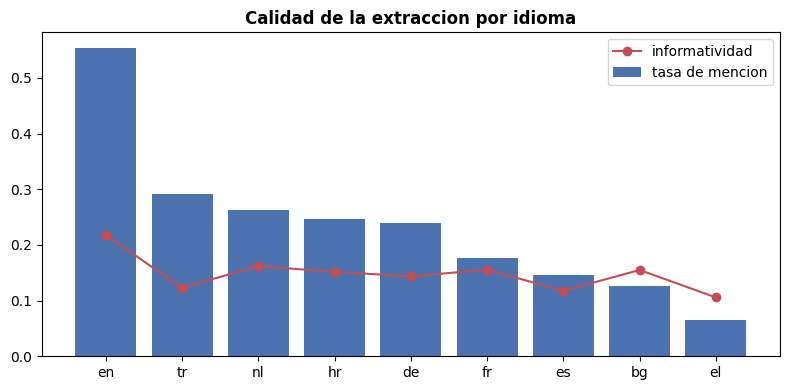

In [29]:
# Mencion, informatividad, estructura del informe y cobertura gold por idioma
lp = pool[['lang', 'rep_len', 'Report']].copy()
lp['mencion'] = M_pool[LABELS].mean(axis=1).values
lp['informatividad'] = (S_raw[LABELS] - S_NOMENTION).abs().mean(axis=1).values
lp['tiene_hallazgos'] = lp['Report'].str.contains(SECTION_RE)
tab7 = lp.groupby('lang').agg(n=('lang', 'size'), mencion=('mencion', 'mean'), informatividad=('informatividad', 'mean'),
                              con_seccion=('tiene_hallazgos', 'mean'), longitud=('rep_len', 'median'))
tab7['gold'] = gold_master['lang'].value_counts().reindex(tab7.index).fillna(0).astype(int)
tab7 = tab7.sort_values('mencion', ascending=False)
tab7.to_csv(f"{CFG['out']}/e7_sesgo_idioma.csv")
display(tab7.round(3))
print('Rango de mencion entre idiomas :', round(tab7['mencion'].max() - tab7['mencion'].min(), 3))
print('Correlacion mencion - longitud :', round(tab7['mencion'].corr(tab7['longitud']), 3))
print('Correlacion mencion - seccion  :', round(tab7['mencion'].corr(tab7['con_seccion']), 3))
print('Idiomas con menos de 5 gold    :', int((tab7['gold'] < 5).sum()), 'de', len(tab7))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tab7.index, tab7['mencion'], color='#4C72B0', label='tasa de mencion')
ax.plot(tab7.index, tab7['informatividad'], 'o-', color='#C44E52', label='informatividad')
ax.set_title('Calidad de la extraccion por idioma', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.savefig(f"{CFG['out']}/e7_sesgo.png", dpi=120); plt.show()

### Discusión
una de las discusiones a dar y las mas fuertes es que la exactitud sola engaña en clases raras y el baseline lo demuestra. MCL saca un 86.2%.

# Persistencia de resultados

In [30]:
# Guardado de modelos, historiales, predicciones y resumen global
torch.save(model_A.state_dict(), f"{CFG['out']}/modelo_A_scratch.pt")
torch.save(model_B.state_dict(), f"{CFG['out']}/modelo_B_resnet50.pt")
hist_A.to_csv(f"{CFG['out']}/hist_A.csv", index=False); hist_B.to_csv(f"{CFG['out']}/hist_B.csv", index=False)
np.save(f"{CFG['out']}/probs_B.npy", probs_B); np.save(f"{CFG['out']}/probs_A.npy", probs_A)

res = {
    'datos': {'estudios_dataset': int(train['StudyInstanceUID'].nunique()), 'series_dataset': int(len(train_series)),
              'estudios_cacheados': len(VOL_IDX), 'train_extendido': len(dl_tr_ext.dataset), 'val_gold': len(dl_va.dataset)},
    'e1': {'auc_macro': float(e1['AUC'].mean()), 'acc_cv': float(ruido['acc_cv'].mean()),
           'baseline': float(ruido['baseline'].mean()), 'tasa_ruido': float(ruido['tasa_ruido'].mean())},
    'e2': tabla_arq.drop(columns='params').set_index('arquitectura').to_dict('index'),
    'e3': e3.to_dict(),
    'e4': abl_df[['config', 'auc_mejor', 'auc_ult5']].to_dict('records'),
    'e6': {'error_prev_antes': float(desb['error_antes'].mean()), 'error_prev_despues': float(desb['error_despues'].mean())},
    'e7': {'rango_mencion': float(tab7['mencion'].max() - tab7['mencion'].min()), 'idiomas_sin_gold_suficiente': int((tab7['gold'] < 5).sum())},
}
with open(f"{CFG['out']}/resumen.json", 'w') as fh:
    json.dump(res, fh, indent=2, default=float)
print(json.dumps(res, indent=2, default=float))
print('\nArchivos:', sorted(os.listdir(CFG['out'])))

{
  "datos": {
    "estudios_dataset": 4407,
    "series_dataset": 24371,
    "estudios_cacheados": 1245,
    "train_extendido": 1142,
    "val_gold": 58
  },
  "e1": {
    "auc_macro": 0.7057209207370679,
    "acc_cv": 0.7404040404040404,
    "baseline": 0.6724137931034483,
    "tasa_ruido": 0.25959595959595966
  },
  "e2": {
    "A  CNN desde cero": {
      "auc_mejor": 0.5892431708657159,
      "auc_ult5": 0.5420266002873432
    },
    "B  ResNet-50": {
      "auc_mejor": 0.605978528222302,
      "auc_ult5": 0.5729788837754923
    }
  },
  "e3": {
    "A  CNN desde cero": {
      "AUC macro": 0.589243170865716,
      "F1 macro @0.5": 0.06227106227106227,
      "F1 macro @prevalencia": 0.4277854376109524,
      "hallazgos con AUC > 0.5": 11.0
    },
    "B  ResNet-50": {
      "AUC macro": 0.6059785282223019,
      "F1 macro @0.5": 0.2367711530502228,
      "F1 macro @prevalencia": 0.4060258290950511,
      "hallazgos con AUC > 0.5": 11.0
    }
  },
  "e4": [
    {
      "config": "R